In [2]:
!pip -q install pytorch-crf seqeval

import re, json, random, time
from collections import Counter
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import torch

SEED = 42
for d in ("data/processed", "models", "docs"):
    Path(d).mkdir(parents=True, exist_ok=True)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
torch 2.11.0+cu130 | cuda: True


## **Skema, Aturan Field, Kamus**

In [3]:
import random as _random

# ---------- 1. Entitas ----------
ENTITY_LABELS: List[str] = [
    "NAMA_PERSONALISASI", "PRODUK", "JUMLAH", "WARNA",
    "UKURAN", "TENGGAT", "TEKS_KARTU", "PENERIMA_ACARA",
]

LABEL_GUIDE: Dict[str, str] = {
    "NAMA_PERSONALISASI": "Nama yang dicetak/dibordir. Bukan nama pemesan. Contoh: 'Rizky & Salsa'.",
    "PRODUK": "Frasa produk lengkap. Contoh: 'sajadah travel', 'hampers lebaran'.",
    "JUMLAH": "Angka/kata bilangan BESERTA satuannya. Contoh: '2 pcs', 'dua lusin'.",
    "WARNA": "Hanya kata warna. Contoh: 'navy', 'dusty pink'.",
    "UKURAN": "Ukuran huruf atau dimensi. Contoh: 'XL', '70x140 cm'.",
    "TENGGAT": "Seluruh frasa waktu. Contoh: 'tanggal 20 november', 'H-3 acara'.",
    "TEKS_KARTU": "Isi ucapan kartu saja, tanpa kata pengantar.",
    "PENERIMA_ACARA": "Penerima atau acara, termasuk 'untuk'/'acara' di depannya. Contoh: 'untuk ibu', 'acara wisuda'.",
}

# ---------- 2. Tag BIO ----------
TAGS: List[str] = ["O"] + [f"{p}-{l}" for l in ENTITY_LABELS for p in ("B", "I")]
TAG2ID: Dict[str, int] = {t: i for i, t in enumerate(TAGS)}
ID2TAG: Dict[int, str] = {i: t for t, i in TAG2ID.items()}

# ---------- 3. Jenis pesanan & aturan field wajib per produk ----------
ORDER_TYPES: List[str] = ["Ready Stock", "Custom Sajadah", "Custom Handuk", "Hampers", "Other"]

# ASUMSI DESAIN (tidak ada data operasional Firaza)
ALWAYS_REQUIRED: List[str] = ["PRODUK", "JUMLAH"]
FIELD_RULES: Dict[str, List[str]] = {   # field wajib tambahan per kategori
    "sajadah": ["NAMA_PERSONALISASI", "UKURAN", "TENGGAT"],
    "handuk":  ["NAMA_PERSONALISASI", "UKURAN", "TENGGAT"],
    "mug":     ["NAMA_PERSONALISASI", "TENGGAT"],
    "hampers": ["TENGGAT"],
    "mukena":  ["UKURAN"],
    "unknown": ["TENGGAT"],
}
CATEGORY_KEYWORDS = [("sajadah", "sajadah"), ("handuk", "handuk"), ("mug", "mug"),
                     ("tumbler", "mug"), ("hampers", "hampers"), ("kado", "hampers"),
                     ("mukena", "mukena")]
ORDER_TYPE_CATEGORY = {"Custom Sajadah": "sajadah", "Custom Handuk": "handuk",
                       "Hampers": "hampers", "Ready Stock": "mukena"}


def category_of(product_text) -> str:
    p = (product_text or "").lower()
    for kw, cat in CATEGORY_KEYWORDS:
        if kw in p:
            return cat
    return "unknown"


def missing_fields(entities: Dict[str, List[str]], order_type=None) -> List[str]:
    """Label wajib yang masih kosong. Tidak menebak nilai apa pun.
    Kategori dari kata kunci produk; kalau gagal (mis. typo), pakai jenis pesanan."""
    products = entities.get("PRODUK") or []
    cat = category_of(products[0] if products else None)
    if cat == "unknown" and order_type:
        cat = ORDER_TYPE_CATEGORY.get(order_type, "unknown")
    needed = ALWAYS_REQUIRED + FIELD_RULES[cat]
    return [f for f in needed if not entities.get(f)]


# ---------- 4. Kamus ----------
# Nama dipisah per split supaya tidak ada nama yang muncul di dua split.
_REAL_NAMES = {
    "train": ["Aisyah", "Budi", "Citra", "Dimas", "Eka", "Farhan", "Gita", "Hana",
              "Indra", "Jihan", "Kiki", "Laras", "Maya", "Naufal", "Okta", "Putri",
              "Rizky", "Salsa", "Tegar", "Umar", "Vina", "Wulan", "Yusuf", "Zahra",
              "Alya", "Bagas", "Dewi", "Fikri", "Hafiz", "Intan"],
    "val": ["Nadia", "Reza", "Siti", "Taufik", "Ulfa", "Wahyu", "Yoga", "Zaki", "Bella", "Fajar"],
    "test": ["Amira", "Cahyo", "Davina", "Erlangga", "Fadila", "Galih", "Hilda",
             "Ilham", "Jasmine", "Kevin"],
}
_BLOCKED = {"nama", "namanya", "mama", "papa", "kaka", "bisa", "mau", "sama", "tamu",
            "satu", "dua", "tiga", "lima", "ibu", "adik", "nenek", "guru", "mug",
            "hari", "bulan", "tahun", "kado", "warna", "paket", "stok", "kartu"}


def _synthetic_names(n: int, seed: int = 7) -> List[str]:
    """Nama bergaya Indonesia dari suku kata; jumlah besar supaya tidak bisa dihafal."""
    rng = _random.Random(seed)
    cons = ["b", "c", "d", "f", "g", "h", "j", "k", "l", "m", "n", "r", "s", "t",
            "w", "y", "z", "sy", "kh"]
    vows = ["a", "i", "u", "e", "o", "a", "i"]
    ends = ["", "", "n", "h", "ah", "ni", "ra", "ya", "na", "a", "l", "m", "ka"]
    known = {x.lower() for v in _REAL_NAMES.values() for x in v}
    out = set()
    while len(out) < n:
        k = rng.choice([2, 2, 3])
        w = "".join(rng.choice(cons) + rng.choice(vows) for _ in range(k)) + rng.choice(ends)
        if len(w) >= 4 and w not in known and w not in _BLOCKED:
            out.add(w)
    return sorted(w.capitalize() for w in out)


_extra = _synthetic_names(400)
_random.Random(11).shuffle(_extra)
_c1, _c2 = int(len(_extra) * 0.70), int(len(_extra) * 0.85)
NAMES_BY_SPLIT: Dict[str, List[str]] = {
    "train": _REAL_NAMES["train"] + _extra[:_c1],
    "val": _REAL_NAMES["val"] + _extra[_c1:_c2],
    "test": _REAL_NAMES["test"] + _extra[_c2:],
}

PRODUCT_TERMS: Dict[str, str] = {   # istilah produk -> jenis pesanan
    "sajadah": "Custom Sajadah", "sajadah travel": "Custom Sajadah",
    "sajadah anak": "Custom Sajadah", "sajadah bordir": "Custom Sajadah",
    "handuk": "Custom Handuk", "handuk mandi": "Custom Handuk",
    "handuk bordir": "Custom Handuk", "handuk kimono": "Custom Handuk",
    "handuk bayi": "Custom Handuk",
    "hampers": "Hampers", "hampers lebaran": "Hampers", "hampers ramadan": "Hampers",
    "hampers wisuda": "Hampers", "kado pernikahan": "Hampers", "paket kado": "Hampers",
    "mukena": "Ready Stock", "tumbler": "Other", "mug": "Other",
}

COLORS = ["navy", "maroon", "hitam", "putih", "abu-abu", "hijau sage", "dusty pink",
          "cream", "coklat", "biru muda", "emerald", "mocca", "tosca", "ungu"]
SIZE_LETTERS = ["S", "M", "L", "XL", "XXL"]
SIZE_DIMS = ["30x50", "50x100", "60x120", "70x140", "100x200"]
SIZE_UNITS = ["cm", ""]          # kadang customer lupa menulis satuan
QTY_WORDS = {"satu": 1, "dua": 2, "tiga": 3, "empat": 4, "lima": 5, "sepuluh": 10,
             "dua belas": 12, "dua puluh": 20, "lusin": 12}
QTY_UNITS = ["pcs", "buah", "set", "pasang", "lusin", "biji"]
EVENTS = ["nikahan", "pernikahan", "ulang tahun", "wisuda", "lebaran", "aqiqah",
          "tunangan", "umroh", "reuni", "syukuran"]
RECIPIENTS = ["ibu", "bapak", "mama", "papa", "kakak", "adik", "calon suami",
              "calon istri", "guru", "sahabat", "mertua", "nenek"]
MONTHS = ["januari", "februari", "maret", "april", "mei", "juni", "juli",
          "agustus", "september", "oktober", "november", "desember"]
DEADLINE_RELATIVE = ["besok", "lusa", "minggu depan", "bulan depan", "akhir bulan",
                     "secepatnya", "hari jumat", "H-3 acara", "H-7 acara"]
CARD_TEXTS = [
    "Semoga selalu dalam lindungan Allah", "Terima kasih sudah menjadi sahabat terbaik",
    "Selamat Idul Fitri, mohon maaf lahir dan batin", "Happy birthday, semoga panjang umur",
    "Congratulations on your wedding", "Selamat atas kelulusanmu",
    "Semoga berkah dan bahagia selalu", "Barakallah atas pernikahan kalian",
    "Doa terbaik untuk kalian berdua", "Sukses terus ya, bangga sama kamu",
    "Selamat atas kelahiran si kecil", "Semoga umrahnya mabrur",
]

# ---------- 5. Cek cepat ----------
s = {k: set(v) for k, v in NAMES_BY_SPLIT.items()}
assert not (s["train"] & s["val"]) and not (s["train"] & s["test"]) and not (s["val"] & s["test"]), "nama bocor antar split"
assert len(TAGS) == 1 + 2 * len(ENTITY_LABELS)
assert "UKURAN" not in missing_fields({"PRODUK": ["mug"], "JUMLAH": ["2 pcs"],
                                       "NAMA_PERSONALISASI": ["Aisyah"], "TENGGAT": ["besok"]})
assert "UKURAN" in missing_fields({"PRODUK": ["sjadah"], "JUMLAH": ["2 pc"]}, "Custom Sajadah")
print("Skema OK | jumlah tag:", len(TAGS), "| nama per split:", {k: len(v) for k, v in NAMES_BY_SPLIT.items()})

Skema OK | jumlah tag: 17 | nama per split: {'train': 310, 'val': 70, 'test': 70}


## **Tokenizer**

In [4]:
_TOKEN_RE = re.compile(r"\w+|[^\w\s]", re.UNICODE)
_ATTACH_PREV = {",", ".", "!", "?", ";", ":", ")", "-", "/", "%"}
_ATTACH_NEXT = {"(", "-", "/"}


def tokenize(text: str) -> List[str]:
    """Kata/angka utuh = 1 token, tiap tanda baca = 1 token."""
    return _TOKEN_RE.findall(text)


def tokenize_with_offsets(text: str) -> List[Tuple[str, int, int]]:
    """Token yang sama dengan tokenize(), plus posisi karakter (start, end)."""
    return [(m.group(), m.start(), m.end()) for m in _TOKEN_RE.finditer(text)]


def detokenize(tokens: List[str]) -> str:
    """Kebalikan tokenize (spasi dirapikan): tokenize(detokenize(t)) == t."""
    out, quote_open, no_space = [], False, True
    for tok in tokens:
        if tok == '"':
            if not quote_open:
                if out:
                    out.append(" ")
                out.append(tok)
                quote_open, no_space = True, True
            else:
                out.append(tok)
                quote_open, no_space = False, False
            continue
        if not out or tok in _ATTACH_PREV or no_space:
            out.append(tok)
        else:
            out.append(" " + tok)
        no_space = tok in _ATTACH_NEXT
    return "".join(out)


_s = 'halo kak, pesan sajadah abu-abu "Selamat wisuda, sukses" tgl 20/11 H-3 acara'
_t = tokenize(_s)
assert tokenize(detokenize(_t)) == _t
print("Tokenizer OK:", _t[:8], "...")

Tokenizer OK: ['halo', 'kak', ',', 'pesan', 'sajadah', 'abu', '-', 'abu'] ...


## **Konfigurasi dan Template**

In [5]:
# kategori yang punya pilihan ukuran (sesuai aturan produk)
SIZE_CATEGORIES = {"sajadah", "handuk", "mukena"}
NO_SIZE_FOR_OTHER_PRODUCTS = True

N_TRAIN, N_VAL, N_TEST = 6000, 800, 800

# Template = list klausa. "[...]" = klausa opsional. Keluarga template dipisah per split.
TEMPLATES = {
    "train": {
        "custom": [
            ["mau pesan {PRODUK}", "{JUMLAH}", "nama yang dibordir {NAMA_PERSONALISASI}",
             "[warna {WARNA}]", "[ukuran {UKURAN}]", "[butuh {TENGGAT}]"],
            ["order {PRODUK} {JUMLAH}", "namanya {NAMA_PERSONALISASI}",
             "[warnanya {WARNA}]", "[deadline {TENGGAT}]"],
            ["bisa custom {PRODUK} {WARNA}", "[mau {JUMLAH}]",
             "tulisan nama {NAMA_PERSONALISASI}", "[selesai {TENGGAT}]"],
            ["pesan {JUMLAH} {PRODUK} {PENERIMA_ACARA}", "nama {NAMA_PERSONALISASI}",
             "[warna {WARNA}]", "[sebelum {TENGGAT}]"],
            ["{PRODUK} {JUMLAH}", "nama {NAMA_PERSONALISASI}", "[ukuran {UKURAN}]",
             "[{PENERIMA_ACARA}]"],
            ["tolong buatkan {PRODUK} dengan nama {NAMA_PERSONALISASI}", "{JUMLAH}",
             "[ukuran {UKURAN}]", "[warna {WARNA}]", "[butuh {TENGGAT}]"],
        ],
        "hampers": [
            ["mau pesan {PRODUK}", "{JUMLAH}", "[{PENERIMA_ACARA}]",
             '[kartu ucapan tulisannya "{TEKS_KARTU}"]', "[butuh {TENGGAT}]"],
            ["order {PRODUK} {JUMLAH}", "[tema warna {WARNA}]",
             '[kartunya: "{TEKS_KARTU}"]', "[dikirim {TENGGAT}]"],
            ["{PRODUK} {PENERIMA_ACARA}", "jumlah {JUMLAH}", "[tema {WARNA}]",
             '[kartu ucapan "{TEKS_KARTU}"]', "[deadline {TENGGAT}]"],
        ],
        "plain": [
            ["ready {PRODUK}?", "[warna {WARNA}]", "[ukuran {UKURAN}]", "{JUMLAH}"],
            ["beli {JUMLAH} {PRODUK}", "[warna {WARNA}]", "[butuh {TENGGAT}]"],
            ["stok {PRODUK} {WARNA} ada?", "[mau {JUMLAH}]", "[ukuran {UKURAN}]"],
        ],
    },
    "val": {
        "custom": [
            ["ada {PRODUK} bisa request nama?", "namanya {NAMA_PERSONALISASI}", "{JUMLAH}",
             "[warna {WARNA}]", "[perlu {TENGGAT}]"],
            ["saya butuh {JUMLAH} {PRODUK}", "bordir {NAMA_PERSONALISASI}",
             "[ukuran {UKURAN}]", "[kirim {TENGGAT}]"],
            ["pengen {PRODUK} warna {WARNA}", "isi nama {NAMA_PERSONALISASI}",
             "[jumlahnya {JUMLAH}]", "[harus jadi {TENGGAT}]"],
            ["{PRODUK} {PENERIMA_ACARA}", "nama {NAMA_PERSONALISASI}", "{JUMLAH}",
             "[mohon selesai {TENGGAT}]"],
        ],
        "hampers": [
            ["cari {PRODUK}", "sebanyak {JUMLAH}", "[{PENERIMA_ACARA}]",
             '[tolong tulis di kartu "{TEKS_KARTU}"]', "[kirim {TENGGAT}]"],
            ["pesan {JUMLAH} {PRODUK}", "[warna {WARNA}]",
             '[ucapan kartu: "{TEKS_KARTU}"]', "[perlu {TENGGAT}]"],
        ],
        "plain": [
            ["{PRODUK} masih ada?", "[warna {WARNA}]", "[ambil {JUMLAH}]", "[ukuran {UKURAN}]"],
            ["mau beli {PRODUK} {JUMLAH}", "[sampai {TENGGAT}]", "[warna {WARNA}]"],
        ],
    },
    "test": {
        "custom": [
            ["boleh pesan {PRODUK}?", "personalisasi {NAMA_PERSONALISASI}", "totalnya {JUMLAH}",
             "[maunya {WARNA}]", "[size {UKURAN}]", "[dipakai {TENGGAT}]"],
            ["order custom {PRODUK} {PENERIMA_ACARA}", "cetak nama {NAMA_PERSONALISASI}",
             "qty {JUMLAH}", "[tolong siap {TENGGAT}]"],
            ["{JUMLAH} {PRODUK} ya", "tertulis {NAMA_PERSONALISASI}",
             "[warna dasar {WARNA}]", "[tenggat {TENGGAT}]"],
            ["mau tanya, {PRODUK} dengan nama {NAMA_PERSONALISASI} bisa?", "butuh {JUMLAH}",
             "[warna {WARNA}]", "[sebelum {TENGGAT}]"],
        ],
        "hampers": [
            ["mau {PRODUK} {JUMLAH}", "[{PENERIMA_ACARA}]",
             '[isi kartu "{TEKS_KARTU}"]', "[sebelum {TENGGAT}]"],
            ["bisa {JUMLAH} {PRODUK}?", "[bertema {WARNA}]",
             '[kartunya bertuliskan "{TEKS_KARTU}"]', "[butuh {TENGGAT}]"],
        ],
        "plain": [
            ["cek stok {PRODUK}", "[maunya {WARNA}]", "[sebanyak {JUMLAH}]", "[ukuran {UKURAN}]"],
            ["{JUMLAH} {PRODUK} {WARNA} tersedia?", "[perlu {TENGGAT}]"],
        ],
    },
}

# template train tambahan (variasi; val/test tidak disentuh)
TEMPLATES["train"]["custom"] += [
    ["halo, aku mau {PRODUK}", "namanya {NAMA_PERSONALISASI} ya", "{JUMLAH}",
     "[warna {WARNA}]", "[tenggatnya {TENGGAT}]"],
    ["pesan {PRODUK} {WARNA} {JUMLAH}", "nama bordir: {NAMA_PERSONALISASI}",
     "[ukuran {UKURAN}]", "[maksimal {TENGGAT}]"],
    ["{JUMLAH} {PRODUK} ya kak", "isi nama {NAMA_PERSONALISASI}",
     "[warna yang {WARNA}]", "[paling lambat {TENGGAT}]"],
    ["request {PRODUK} nama {NAMA_PERSONALISASI}", "sebanyak {JUMLAH}",
     "[ukuran {UKURAN}]", "[{PENERIMA_ACARA}]", "[paling lambat {TENGGAT}]"],
    ["kak, {PRODUK} custom dong", "nama {NAMA_PERSONALISASI}", "{JUMLAH}",
     "[{PENERIMA_ACARA}]", "[warna {WARNA}]"],
]
TEMPLATES["train"]["hampers"] += [
    ["kak mau {PRODUK}", "sebanyak {JUMLAH}", "[{PENERIMA_ACARA}]",
     '[kartu: "{TEKS_KARTU}"]', "[paling lambat {TENGGAT}]"],
    ["{JUMLAH} {PRODUK}", "[warna {WARNA}]", '[di kartu tulis "{TEKS_KARTU}"]',
     "[butuh {TENGGAT}]"],
]
TEMPLATES["train"]["plain"] += [
    ["{PRODUK} {WARNA} ada?", "mau {JUMLAH}", "[ukuran {UKURAN}]"],
    ["mau beli {PRODUK}", "[warna {WARNA}]", "[{JUMLAH}]", "[butuh {TENGGAT}]"],
]

KINDS = ["custom", "hampers", "plain"]
KIND_WEIGHTS = [0.50, 0.25, 0.25]
KIND_ORDER_TYPES = {
    "custom": ("Custom Sajadah", "Custom Handuk"),
    "hampers": ("Hampers",),
    "plain": ("Ready Stock", "Other"),
}
print({sp: sum(len(v) for v in t.values()) for sp, t in TEMPLATES.items()}, "template per split")

{'train': 21, 'val': 8, 'test': 8} template per split


Augmentasi, Sampler, Fungsi Pembuat Data

In [6]:
# ---------- Augmentasi (gaya chat asli) ----------
ABBR = {"yang": "yg", "tanggal": "tgl", "untuk": "utk", "tolong": "tlg", "dengan": "dgn",
        "tidak": "gak", "bisa": "bs", "sebelum": "sblm", "pcs": "pc", "buah": "bh",
        "warna": "wrn", "ukuran": "uk", "jumlah": "jml", "kirim": "krm", "nama": "nm",
        "sebanyak": "sbnyk", "deadline": "dl", "tersedia": "tsedia", "butuh": "btuh"}
GREETINGS = ["halo kak", "hai kak", "permisi kak", "kak", "min", "halo min",
             "assalamualaikum", "selamat pagi kak", "selamat siang kak"]
CLOSINGS = ["ya", "makasih", "terima kasih kak", "thanks ya", "mohon info",
            "ditunggu kak", "makasih kak"]
FILLERS = ["yang", "ya", "kira-kira", "pokoknya", "nih", "aja", "kalau", "jenis",
           "model", "utama", "tuh", "gitu"]


def typo(word: str, rng: random.Random) -> str:
    i = rng.randrange(1, len(word) - 1)          # huruf pertama dipertahankan
    op = rng.choice(["swap", "drop", "dup", "vowel"])
    if op == "swap":
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]
    if op == "drop":
        return word[:i] + word[i + 1:]
    if op == "dup":
        return word[:i] + word[i] + word[i:]
    if word[i].lower() in "aiueo":
        return word[:i] + rng.choice("aiueo") + word[i + 1:]
    return word


def augment(tokens, tags, rng, fillers=False):
    """Semua operasi aman untuk label BIO. Kata pengisi hanya dipakai untuk train."""
    tokens, tags = list(tokens), list(tags)
    if rng.random() < 0.6:   # singkatan
        tokens = [ABBR.get(t.lower(), t) if rng.random() < 0.5 else t for t in tokens]
    if rng.random() < 0.6:   # typo
        tokens = [typo(t, rng) if (t.isalpha() and len(t) >= 4 and rng.random() < 0.07) else t
                  for t in tokens]
    if fillers and rng.random() < 0.35:   # kata pengisi sebelum entitas
        nt, ng = [], []
        for t, g in zip(tokens, tags):
            if g.startswith("B-") and rng.random() < 0.25:
                f = tokenize(rng.choice(FILLERS))
                nt += f
                ng += ["O"] * len(f)
            nt.append(t)
            ng.append(g)
        tokens, tags = nt, ng
    if rng.random() < 0.5:   # sapaan di depan
        pre = tokenize(rng.choice(GREETINGS))
        if rng.random() < 0.5:
            pre.append(",")
        tokens, tags = pre + tokens, ["O"] * len(pre) + tags
    if rng.random() < 0.35:  # penutup
        suf = tokenize(rng.choice(CLOSINGS))
        tokens, tags = tokens + suf, tags + ["O"] * len(suf)
    if rng.random() < 0.4:   # huruf kecil semua
        tokens = [t.lower() for t in tokens]
    return tokens, tags


# ---------- Sampler nilai entitas ----------
def pool_for_split(pool: List[str], split: str) -> List[str]:
    """Bagi pool terbuka (teks kartu) jadi train/val/test tanpa tumpang tindih."""
    n = len(pool)
    n_test, n_val = max(1, round(0.2 * n)), max(1, round(0.15 * n))
    n_train = n - n_val - n_test
    assert n_train >= 1, "pool terlalu kecil untuk dibagi tiga split"
    return {"train": pool[:n_train], "val": pool[n_train:n_train + n_val],
            "test": pool[n_train + n_val:]}[split]


class ValueSampler:
    def __init__(self, split: str, rng: random.Random):
        self.rng = rng
        self.names = NAMES_BY_SPLIT[split]
        self.cards = pool_for_split(CARD_TEXTS, split)

    def sample(self, label: str, cache: Dict[str, str]) -> str:
        if label not in cache:                      # nilai yang sama dalam satu pesan
            cache[label] = getattr(self, f"_{label}")()
        return cache[label]

    def _NAMA_PERSONALISASI(self):
        if self.rng.random() < 0.7:
            return self.rng.choice(self.names)
        a, b = self.rng.sample(self.names, 2)
        return f"{a} {self.rng.choice(['&', 'dan'])} {b}"

    def _JUMLAH(self):
        r = self.rng
        if r.random() < 0.7:
            n = r.choice([1, 2, 3, 4, 5, 6, 10, 12, 20, 24, 25, 30, 50, 100])
            sep = "" if r.random() < 0.15 else " "
            return f"{n}{sep}{r.choice(QTY_UNITS)}"
        word = r.choice([w for w in QTY_WORDS if w != "lusin"])
        units = [u for u in QTY_UNITS
                 if not (u == "lusin" and word in ("sepuluh", "dua belas", "dua puluh"))]
        return f"{word} {r.choice(units)}"

    def _WARNA(self):
        return self.rng.choice(COLORS)

    def _UKURAN(self):
        r = self.rng
        if r.random() < 0.4:
            return r.choice(SIZE_LETTERS)
        return f"{r.choice(SIZE_DIMS)} {r.choice(SIZE_UNITS)}".strip()

    def _TENGGAT(self):
        r = self.rng
        d, m, x = r.randint(1, 30), r.choice(MONTHS), r.random()
        if x < 0.3:
            return f"tanggal {d} {m}"
        if x < 0.5:
            return f"{d} {m}"
        if x < 0.6:
            return f"tgl {d} {m}"
        if x < 0.7:
            return f"{d}/{r.randint(1, 12)}"
        return r.choice(DEADLINE_RELATIVE)

    def _TEKS_KARTU(self):
        return self.rng.choice(self.cards)

    def _PENERIMA_ACARA(self):
        r, x = self.rng, self.rng.random()
        if x < 0.5:
            return f"untuk {r.choice(RECIPIENTS)}"
        if x < 0.8:
            return r.choice(EVENTS)
        return f"acara {r.choice(EVENTS)}"


# ---------- Render template -> token + BIO ----------
PH = re.compile(r"(\{[A-Z_]+\})")


def resolve_clauses(template, rng, keep_opt=0.8, keep_req=0.92):
    out = []
    for clause in template:
        optional = clause.startswith("[") and clause.endswith("]")
        text = clause[1:-1] if optional else clause
        keep = True if "{PRODUK}" in text else rng.random() < (keep_opt if optional else keep_req)
        if keep:
            out.append(text)
    return out


def build_segments(clauses, value_fn, rng, shuffle_p=0.35):
    clauses = list(clauses)
    if rng.random() < shuffle_p:
        rng.shuffle(clauses)
    segs = []
    for i, clause in enumerate(clauses):
        if i:
            segs.append((rng.choice([", ", " ", ". ", " "]), None))
        for part in PH.split(clause):
            if not part:
                continue
            if part.startswith("{"):
                label = part[1:-1]
                assert label in ENTITY_LABELS, f"label template tidak dikenal: {label}"
                segs.append((value_fn(label), label))
            else:
                segs.append((part, None))
    return segs


def segments_to_bio(segs):
    tokens, tags = [], []
    for text, label in segs:
        for j, tok in enumerate(tokenize(text)):
            tokens.append(tok)
            tags.append("O" if label is None else f"{'B' if j == 0 else 'I'}-{label}")
    return tokens, tags


def extract_spans(tokens, tags):
    """BIO -> [(label, teks)]. Dipakai statistik dan evaluasi."""
    spans, cur = [], None
    for tok, tag in zip(tokens, tags):
        if tag.startswith("B-"):
            if cur:
                spans.append(cur)
            cur = [tag[2:], [tok]]
        elif tag.startswith("I-") and cur and cur[0] == tag[2:]:
            cur[1].append(tok)
        else:
            if cur:
                spans.append(cur)
            cur = None
    if cur:
        spans.append(cur)
    return [(label, detokenize(toks)) for label, toks in spans]


# ---------- Generate satu split ----------
def generate_split(split: str, n: int, rng: random.Random) -> List[dict]:
    sampler = ValueSampler(split, rng)
    products = {k: [t for t, o in PRODUCT_TERMS.items() if o in ots]
                for k, ots in KIND_ORDER_TYPES.items()}
    records, seen, attempts = [], set(), 0
    while len(records) < n and attempts < n * 30:
        attempts += 1
        kind = rng.choices(KINDS, weights=KIND_WEIGHTS)[0]
        t_idx = rng.randrange(len(TEMPLATES[split][kind]))
        template = TEMPLATES[split][kind][t_idx]
        product = rng.choice(products[kind])
        cache = {"PRODUK": product}
        if NO_SIZE_FOR_OTHER_PRODUCTS and category_of(product) not in SIZE_CATEGORIES:
            template = [c for c in template if "{UKURAN}" not in c]

        clauses = resolve_clauses(template, rng)
        segs = build_segments(clauses, lambda lb: sampler.sample(lb, cache), rng)
        tokens, tags = segments_to_bio(segs)

        augmented = rng.random() >= 0.15          # 15% pesan dibiarkan bersih
        if augmented:
            tokens, tags = augment(tokens, tags, rng, fillers=(split == "train"))

        text = detokenize(tokens)
        if tokenize(text) != tokens or text.lower() in seen:
            continue
        seen.add(text.lower())
        assert len(tokens) == len(tags) and all(t in TAG2ID for t in tags)
        records.append({"id": f"{split}-{len(records):05d}", "split": split, "text": text,
                        "tokens": tokens, "tags": tags, "order_type": PRODUCT_TERMS[product],
                        "template_id": f"{split}-{kind}-{t_idx}", "augmented": augmented})
    return records


# ---------- Cek kebocoran & statistik ----------
def name_tokens(records) -> set:
    out = set()
    for r in records:
        for label, text in extract_spans(r["tokens"], r["tags"]):
            if label == "NAMA_PERSONALISASI":
                out |= {t.lower() for t in tokenize(text)} - {"&", "dan"}
    return out


def drop_overlap(records, reference):
    ref = {r["text"].lower() for r in reference}
    return [r for r in records if r["text"].lower() not in ref]


def save_jsonl(path, records):
    with open(path, "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

## **Dataset**

In [7]:
rng = random.Random(SEED)
data = {"train": generate_split("train", N_TRAIN, rng),
        "val": generate_split("val", N_VAL, rng),
        "test": generate_split("test", N_TEST, rng)}

# buang teks yang kebetulan sama antar split
data["val"] = drop_overlap(data["val"], data["train"])
data["test"] = drop_overlap(data["test"], data["train"] + data["val"])

# cek nama bocor (peringatan, bukan error: typo bisa menciptakan kebetulan)
tr_names = name_tokens(data["train"])
for sp in ("val", "test"):
    leak = tr_names & name_tokens(data[sp])
    print(f"Nama bocor train vs {sp}:", sorted(leak) if leak else "tidak ada")

for sp, recs in data.items():
    save_jsonl(f"data/processed/{sp}.jsonl", recs)

# statistik
total = sum(len(v) for v in data.values())
rows = {}
for sp, recs in data.items():
    ent = Counter(l for r in recs for l, _ in extract_spans(r["tokens"], r["tags"]))
    rows[sp] = {"pesan": len(recs), "% dari total": round(100 * len(recs) / total, 1),
                "rata2 token": round(sum(len(r["tokens"]) for r in recs) / len(recs), 1),
                **{l: ent.get(l, 0) for l in ENTITY_LABELS}}
stats_df = pd.DataFrame(rows).T
display(stats_df)
json.dump(rows, open("data/processed/stats.json", "w"), indent=2)

print("\nJenis pesanan per split:")
display(pd.DataFrame({sp: Counter(r["order_type"] for r in recs) for sp, recs in data.items()}).fillna(0).astype(int))

print("\n--- contoh train ---")
for r in data["train"][:6]:
    print(r["text"])
    print("   ", r["order_type"], extract_spans(r["tokens"], r["tags"]))

Nama bocor train vs val: tidak ada
Nama bocor train vs test: tidak ada


,pesan,% dari total,rata2 token,NAMA_PERSONALISASI,PRODUK,JUMLAH,WARNA,UKURAN,TENGGAT,TEKS_KARTU,PENERIMA_ACARA
train,6000.0,78.9,16.9,2770.0,6000.0,5588.0,4093.0,1312.0,3676.0,1195.0,1691.0
val,800.0,10.5,16.8,357.0,800.0,740.0,429.0,115.0,542.0,171.0,173.0
test,800.0,10.5,16.7,365.0,800.0,759.0,504.0,112.0,544.0,164.0,173.0



Jenis pesanan per split:


,train,val,test
Hampers,1502,201,211
Custom Handuk,1664,232,214
Custom Sajadah,1325,152,183
Ready Stock,499,78,61
Other,1010,137,131



--- contoh train ---
mau pesan paket kado, 1buah nikahan kartu ucapan tulisannya "Semoga berkah dan bahaiga selalu" butuh tanggal 15 oktober
    Hampers [('PRODUK', 'paket kado'), ('JUMLAH', '1buah'), ('PENERIMA_ACARA', 'nikahan'), ('TEKS_KARTU', 'Semoga berkah dan bahaiga selalu'), ('TENGGAT', 'tanggal 15 oktober')]
kak, pesan 100 set handuk untuk mertua
    Custom Handuk [('JUMLAH', '100 set'), ('PRODUK', 'handuk'), ('PENERIMA_ACARA', 'untuk mertua')]
butuh tanggal 13 mei. warna putih 25 set hampers lebaran
    Hampers [('TENGGAT', 'tanggal 13 mei'), ('WARNA', 'putih'), ('JUMLAH', '25 set'), ('PRODUK', 'hampers lebaran')]
halo min tiga lusin hampers ramadan warna maroon, di kartu tulis "Terima kasih sudah menjadi sahabat terbaik" butuh hari jumat
    Hampers [('JUMLAH', 'tiga lusin'), ('PRODUK', 'hampers ramadan'), ('WARNA', 'maroon'), ('TEKS_KARTU', 'Terima kasih sudah menjadi sahabat terbaik'), ('TENGGAT', 'hari jumat')]
halo min, mau pesan kado pernikahan. 4 pcs, pernikahan
    H

## **Preprocessing**

In [8]:
from torch.utils.data import DataLoader, Dataset
from seqeval.metrics import classification_report, f1_score

PAD, UNK, NUM = "<PAD>", "<UNK>", "<NUM>"
MAX_WORD_LEN = 20            # karakter per token (dipotong kalau lebih)
assert TAG2ID["O"] == 0      # padding tag = 0 = "O" (aman karena ada mask)


def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def normalize_word(tok: str) -> str:
    """Lowercase; angka murni -> <NUM> (angka sering unik, tidak perlu dihafal)."""
    t = tok.lower()
    return NUM if t.isdigit() else t


class Vocab:
    def __init__(self, itos: List[str]):
        self.itos = itos
        self.stoi = {t: i for i, t in enumerate(itos)}
        self.unk_id = self.stoi[UNK]

    def __len__(self):
        return len(self.itos)

    def encode(self, item: str) -> int:
        return self.stoi.get(item, self.unk_id)

    @classmethod
    def build_words(cls, records, min_freq=2):
        cnt = Counter(normalize_word(t) for r in records for t in r["tokens"])
        words = sorted(w for w, c in cnt.items() if c >= min_freq and w != NUM)
        return cls([PAD, UNK, NUM] + words)

    @classmethod
    def build_chars(cls, records):
        # huruf besar/kecil dipertahankan: kapital adalah petunjuk nama
        chars = sorted({c for r in records for t in r["tokens"] for c in t})
        return cls([PAD, UNK] + chars)


def encode_example(tokens, tags, wv, cv, p_unk_entity=0.0, p_unk_other=0.0, p_char_mask=0.0):
    word_ids, char_ids = [], []
    for tok, tag in zip(tokens, tags):
        wid = wv.encode(normalize_word(tok))
        chars = [cv.encode(c) for c in tok[:MAX_WORD_LEN]]
        p = p_unk_entity if tag != "O" else p_unk_other
        if p > 0 and random.random() < p:
            wid = wv.unk_id
            # kata entitas yang dijatuhkan: sembunyikan juga hurufnya (kadang),
            # supaya model belajar dari KONTEKS, bukan menghafal ejaan
            if tag != "O" and random.random() < p_char_mask:
                chars = [cv.unk_id] * len(chars)
        word_ids.append(wid)
        char_ids.append(chars)
    return {"word_ids": word_ids, "char_ids": char_ids, "tag_ids": [TAG2ID[t] for t in tags]}


class NERDataset(Dataset):
    """train=True mengaktifkan word dropout + penyembunyian karakter (regularisasi)."""
    def __init__(self, records, word_vocab, char_vocab, train=False,
                 p_unk_entity=0.2, p_unk_other=0.12, p_char_mask=0.3):
        self.records, self.wv, self.cv = records, word_vocab, char_vocab
        self.pe, self.po, self.pc = ((p_unk_entity, p_unk_other, p_char_mask)
                                     if train else (0.0, 0.0, 0.0))

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        return encode_example(r["tokens"], r["tags"], self.wv, self.cv, self.pe, self.po, self.pc)


def collate_fn(batch):
    B = len(batch)
    T = max(len(b["word_ids"]) for b in batch)
    C = max(len(c) for b in batch for c in b["char_ids"])
    words = torch.zeros(B, T, dtype=torch.long)
    chars = torch.zeros(B, T, C, dtype=torch.long)
    tags = torch.zeros(B, T, dtype=torch.long)
    mask = torch.zeros(B, T, dtype=torch.bool)
    lengths = torch.zeros(B, dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["word_ids"])
        words[i, :n] = torch.tensor(b["word_ids"])
        tags[i, :n] = torch.tensor(b["tag_ids"])
        mask[i, :n] = True
        lengths[i] = n
        for j, cid in enumerate(b["char_ids"]):
            chars[i, j, :len(cid)] = torch.tensor(cid)
    return {"words": words, "chars": chars, "tags": tags, "mask": mask, "lengths": lengths}


def make_batch(tokens_list, wv, cv):
    """Untuk inferensi: token mentah -> batch tensor."""
    return collate_fn([encode_example(t, ["O"] * len(t), wv, cv) for t in tokens_list])

## **Bangun Vocab & Cek OOV**

In [9]:
train, val, test = (load_jsonl(f"data/processed/{s}.jsonl") for s in ("train", "val", "test"))

# vocab HANYA dari train (val/test tidak boleh mengintip)
word_vocab = Vocab.build_words(train, min_freq=2)
char_vocab = Vocab.build_chars(train)
print(f"Vocab kata: {len(word_vocab)} | vocab karakter: {len(char_vocab)}")


def oov_rate(recs):
    toks = [(t, tg) for r in recs for t, tg in zip(r["tokens"], r["tags"])]
    all_oov = sum(normalize_word(t) not in word_vocab.stoi for t, _ in toks) / len(toks)
    ent = [t for t, tg in toks if tg != "O"]
    ent_oov = sum(normalize_word(t) not in word_vocab.stoi for t in ent) / max(1, len(ent))
    return all_oov, ent_oov


for name, recs in (("train", train), ("val", val), ("test", test)):
    a, e = oov_rate(recs)
    print(f"OOV {name:5s}: semua token {a:.1%} | token entitas {e:.1%}")

dl = DataLoader(NERDataset(train, word_vocab, char_vocab, train=True),
                batch_size=32, shuffle=True, collate_fn=collate_fn)
b = next(iter(dl))
print({k: tuple(v.shape) for k, v in b.items()})
assert b["mask"][:, 0].all()   # syarat pytorch-crf: timestep pertama selalu valid
print("Preprocessing OK")

Vocab kata: 936 | vocab karakter: 71
OOV train: semua token 0.6% | token entitas 0.9%
OOV val  : semua token 17.5% | token entitas 17.0%
OOV test : semua token 19.7% | token entitas 14.6%
{'words': (32, 30), 'chars': (32, 30, 15), 'tags': (32, 30), 'mask': (32, 30), 'lengths': (32,)}
Preprocessing OK


## **Handwritten Text**

In [10]:
%%writefile data/handwritten_raw.txt
sajadah | aku mau pesen [PRODUK: sajadah bordir] nama [NAMA: Aisyah Putri] [JUMLAH: 3 pcs] warna [WARNA: sage green]
sajadah | mau bikin sajadh [PRODUK: sajadah] sbg [PENERIMA: souvenir umroh]
sajadah | kak mau pesan [PRODUK: sajadah bordir] [JUMLAH: 2 pcs] nama [NAMA: Dewi] warna [WARNA: maroon] ya
sajadah | min bisa bikin [PRODUK: sajadah travel] ukuran [UKURAN: 70x110] warna [WARNA: navy]?
sajadah | permisi kak mau order [JUMLAH: 5] [PRODUK: sajadah custom] untuk acara [PENERIMA: pengajian]
sajadah | sjdh [PRODUK: sajadah] ini rencananya untuk [PENERIMA: jamaah masjid]
sajadah | kak [PRODUK: sajadah] yg [UKURAN: 60x100] ada? mau warna [WARNA: cream]
sajadah | min tolong buatin [PRODUK: sajadah bordir] nama [NAMA: Pak Hendra] selesai [TENGGAT: 10 desember]
sajadah | mau order [JUMLAH: 10 pcs] [PRODUK: sajadah] buat [PENERIMA: souvenir nikahan], warna [WARNA: dusty pink]
sajadah | kak bisa bordir tulisan "[KARTU: Barakallah fii umrik]" di [PRODUK: sajadah]?
sajadah | aku mau pesan [PRODUK: sajadah] untuk [PENERIMA: hadiah pernikahan]
sajadah | kak mau [PRODUK: sajadah travel] [JUMLAH: 2] nama [NAMA: Rani dan Rina] sebelum [TENGGAT: minggu depan]
sajadah | ada [PRODUK: sajadah anak] ukuran [UKURAN: 40x60] ga min
sajadah | pesen [JUMLAH: 12 box] [PRODUK: sajadah bordir] untuk [PENERIMA: hadiah guru], nama [NAMA: SD Harapan Bangsa]
sajadah | butuh [JUMLAH: 10] [PRODUK: sajadah] buat [PENERIMA: acara wisuda]
sajadah | mau [PRODUK: sajadah jumbo] [UKURAN: 100x150], [JUMLAH: 1 pcs] aja
sajadah | kak tolong buatkan [PRODUK: sajadah] [JUMLAH: 20] buat acara [PENERIMA: wisuda tahfidz], butuh [TENGGAT: 25 november]
sajadah | [PRODUK: sajadah travel] [JUMLAH: 3 biji] nama [NAMA: Fira] wrn [WARNA: mocca] bisa min?
sajadah | min aku mau pesen [PRODUK: sajadah bordir], tulis [NAMA: Hj. Siti Aminah], warna [WARNA: gold]
sajadah | pesan [PRODUK: sajadah] untuk [PENERIMA: peserta pengajian]
sajadah | kak mau [JUMLAH: 2 pcs] [PRODUK: sajadah] buat [PENERIMA: kado pernikahan], warna [WARNA: broken white]
sajadah | [PRODUK: sajadah bordir] nama [NAMA: RIZKY] bisa jadi [TENGGAT: besok sore] ga?

handuk | halo min mau pesan [PRODUK: handuk bordir] [JUMLAH: 4 pcs] nama [NAMA: Kevin] warna [WARNA: abu-abu]
handuk | kak [PRODUK: handuk] ukuran [UKURAN: 70x140] ada warna [WARNA: putih]?
handuk | mau order [PRODUK: handuk] buat [PENERIMA: souvenir ulang tahun], [JUMLAH: 30 pcs]
handuk | min bisa bordir nama [NAMA: Zahra] di [PRODUK: handuk]?
handuk | hndukkk [PRODUK: handuk] ini untuk [PENERIMA: hadiah ulang tahun ibu]
handuk | ada [PRODUK: handuk mandi] ukuran [UKURAN: 100x150] untuk [PENERIMA: keluarga besar]?
handuk | kak butuh [JUMLAH: 15 pcs] [PRODUK: handuk bordir] sebelum [TENGGAT: tanggal 1 desember]
handuk | [PRODUK: handuk] warna [WARNA: hitam] nama [NAMA: ANDI] satu aja
handuk | [PRODUK: handuk kecil] buat [PENERIMA: hampers bayi] ready ga min?
handuk | min order [JUMLAH: 100 pcs] [PRODUK: handuk] untuk [PENERIMA: acara kantor]
handuk | bisa tulis "[KARTU: Terima kasih sudah hadir]" di bordir [PRODUK: handuk]?
handuk | kak [PRODUK: handuk] yg [UKURAN: 35x75] bahan cotton ada?
handuk | mau pesan [JUMLAH: 20] [PRODUK: handuk hotel] buat [PENERIMA: karyawan kantor]
handuk | [PRODUK: handuk bordir] [JUMLAH: 5 biji] nama [NAMA: keluarga besar wijaya] wrn [WARNA: coklat]
handuk | min ada [PRODUK: handuk] warna [WARNA: emerald] ukuran [UKURAN: 50x100]?
handuk | mau beli [PRODUK: handuk] buat [PENERIMA: hadiah ibu], bordir nama [NAMA: Mama]
handuk | kak bisa selesai [TENGGAT: jumat ini] kalau pesen [JUMLAH: 20] [PRODUK: handuk]?
handuk | [PRODUK: handuk] [JUMLAH: 3 pcs] warna [WARNA: pink] ukuran [UKURAN: 70x140] untuk [PENERIMA: adek saya]?
handuk | min [PRODUK: handuk bordir] untuk [PENERIMA: souvenir pernikahan] [JUMLAH: 50 pcs] bisa?
handuk | ada [PRODUK: handuk microfiber] ga kak?

hampers | halo kak mau [PRODUK: hampers lebaran] [JUMLAH: 10 box] untuk [PENERIMA: klien kantor]
hampers | min ada [PRODUK: hampers] buat [PENERIMA: guru]? budget nanti aku tanyakan dulu
hampers | mau order [JUMLAH: 5 set] [PRODUK: hampers ulang tahun] warna [WARNA: pastel]
hampers | kak bisa masukin kartu "[KARTU: Selamat Idul Fitri, mohon maaf lahir dan batin]"?
hampers | pesan [PRODUK: hampers bayi] buat [PENERIMA: anak pertama kakak] ya
hampers | min butuh [JUMLAH: 25 box] [PRODUK: hampers] sebelum [TENGGAT: 20 desember] untuk [PENERIMA: acara nikahan]
hampers | ada [PRODUK: hampers wisuda] warna [WARNA: navy]?
hampers | mau [PRODUK: hampers custom] nama penerima [NAMA: Ibu Ratna]
hampers | kak [PRODUK: hampers lebaran] [JUMLAH: 3 pcs] bisa dikirim [TENGGAT: minggu depan]?
hampers | tolong buat [JUMLAH: 12 paket] [PRODUK: hampers] untuk [PENERIMA: peserta seminar], kartu "[KARTU: Terima kasih atas partisipasinya]"
hampers | min ada [PRODUK: hampers cokelat]?
hampers | [PRODUK: hampers wedding] [JUMLAH: 100 box] nama [NAMA: Dinda & Arga]
hampers | kak mau [PRODUK: hampers] untuk [PENERIMA: calon mertua], warna [WARNA: cream] dan [WARNA: gold]
hampers | butuh [PRODUK: hampers] [JUMLAH: 2] aja buat [PENERIMA: teman kantor]
hampers | bisa custom tulisan "[KARTU: Happy Birthday, Bestie!]" untuk [PRODUK: hampers] buat [PENERIMA: sahabat setia]?
hampers | [PRODUK: hampers lebaran] [JUMLAH: 10 lusin] untuk [PENERIMA: rekan kerja] bisa min?
hampers | kak aku mau order [JUMLAH: 8 set] [PRODUK: hampers mukena] untuk [PENERIMA: keluarga]
hampers | tersedia [PRODUK: hampers] warna [WARNA: sage] ukuran box [UKURAN: 25x25x10]?
hampers | tolong siapin [PRODUK: hampers] [JUMLAH: 40 box] sebelum [TENGGAT: akhir bulan] untuk [PENERIMA: acara kelahiran bayi]
hampers | min mau [PRODUK: hampers custom] tapi belum tau isi produknya, buat [PENERIMA: dosen pembimbing]

ready | kak [PRODUK: mukena] warna [WARNA: putih] [UKURAN: L] ready ga?
ready | min stok [PRODUK: sajadah travel] warna [WARNA: hitam] masih ada?
ready | [PRODUK: handuk] [WARNA: maroon] [JUMLAH: 2 pcs] ready kak?
ready | ready [PRODUK: tasbih digital] warna [WARNA: putih]?
ready | min ada [PRODUK: sajadah anak] [UKURAN: 50x70]?
ready | kak stok [PRODUK: handuk microfiber] masih tersedia?
ready | [PRODUK: mukena bordir] warna [WARNA: dusty pink] ada?
ready | [PRODUK: sajadah polos] yg [WARNA: abu] ready brp pcs min
ready | ready kah [PRODUK: tas serut] warna [WARNA: navy]?
ready | kak ada [PRODUK: bantal leher] warna [WARNA: cream]?
ready | mau cek stok [PRODUK: tumbler] warna [WARNA: hitam]
ready | min [PRODUK: pouch] ukuran [UKURAN: 20x15] ada?
ready | [PRODUK: handuk] warna [WARNA: biru] ready?
ready | ada [PRODUK: bantal] bordir nama ga?
ready | ready [PRODUK: totebag] warna [WARNA: broken white] berapa?

other | kak bisa kirim katalog produknya?
other | min ongkir ke Surabaya berapa ya?
other | permisi, toko buka sampai jam berapa?
other | kak pembayaran bisa pakai transfer bank?
other | kalau pesan hari ini estimasi pengerjaan berapa lama?
other | min boleh minta foto asli [PRODUK: sajadah bordir]?
other | apakah bisa dikirim ke luar pulau?
other | kak ada diskon untuk pembelian banyak?
other | mau tanya cara perawatan [PRODUK: handuk] supaya awet
other | min bisa custom logo perusahaan di [PRODUK: totebag]?

Writing data/handwritten_raw.txt


## **Data BIO**

In [11]:
ALIAS = {label: label for label in ENTITY_LABELS}
ALIAS.update({"NAMA": "NAMA_PERSONALISASI", "KARTU": "TEKS_KARTU",
              "PENERIMA": "PENERIMA_ACARA", "ACARA": "PENERIMA_ACARA"})
ORDER_ALIAS = {"sajadah": "Custom Sajadah", "handuk": "Custom Handuk",
               "hampers": "Hampers", "ready": "Ready Stock", "other": "Other"}
SPAN_RE = re.compile(r"\[([A-Za-z_]+):\s*([^\]]+?)\s*\]")


def parse_body(body):
    """Buang penanda [LABEL: teks]; kembalikan (teks bersih, [(label, start, end)])."""
    parts, spans, pos, last = [], [], 0, 0
    for m in SPAN_RE.finditer(body):
        before = body[last:m.start()]
        parts.append(before)
        pos += len(before)
        label = ALIAS.get(m.group(1).upper())
        if label is None:
            raise ValueError(f"label tidak dikenal: '{m.group(1)}'")
        txt = m.group(2)
        spans.append((label, pos, pos + len(txt)))
        parts.append(txt)
        pos += len(txt)
        last = m.end()
    parts.append(body[last:])
    clean = "".join(parts)
    if "[" in clean or "]" in clean:
        raise ValueError("ada tanda [ atau ] yang tidak berpasangan / format salah")
    return clean, spans


def handwritten_to_bio(clean, spans):
    toks = tokenize_with_offsets(clean)
    tags = ["O"] * len(toks)
    for label, s, e in spans:
        idx = [i for i, (_, a, b) in enumerate(toks) if a >= s and b <= e]
        if not idx:
            raise ValueError(f"span '{clean[s:e]}' tidak cocok dengan token apa pun")
        if toks[idx[0]][1] != s or toks[idx[-1]][2] != e:
            raise ValueError(f"span '{clean[s:e]}' memotong sebagian token (tandai kata utuh)")
        if any(tags[i] != "O" for i in idx):
            raise ValueError(f"span '{clean[s:e]}' tumpang tindih dengan span lain")
        for k, i in enumerate(idx):
            tags[i] = f"{'B' if k == 0 else 'I'}-{label}"
    return [t for t, _, _ in toks], tags


def build_handwritten(raw_path="data/handwritten_raw.txt", out_path="data/handwritten_test.jsonl"):
    if not Path(raw_path).exists():
        print(f"(lewati: {raw_path} belum ada)")
        return []
    records, errors, seen = [], [], set()
    for ln, line in enumerate(Path(raw_path).read_text(encoding="utf-8").splitlines(), 1):
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        try:
            if "|" not in line:
                raise ValueError("tidak ada tanda '|' (format: jenis | pesan)")
            jenis, body = (x.strip() for x in line.split("|", 1))
            order = None
            if jenis:
                if jenis.lower() not in ORDER_ALIAS:
                    raise ValueError(f"jenis '{jenis}' tidak dikenal ({', '.join(ORDER_ALIAS)})")
                order = ORDER_ALIAS[jenis.lower()]
            clean, spans = parse_body(body)
            tokens, tags = handwritten_to_bio(clean, spans)
            if clean.lower() in seen:
                raise ValueError("pesan duplikat")
            seen.add(clean.lower())
            records.append({"id": f"hw-{len(records):04d}", "split": "handwritten", "text": clean,
                            "tokens": tokens, "tags": tags, "order_type": order,
                            "template_id": "handwritten", "augmented": False})
        except ValueError as e:
            errors.append(f"  baris {ln}: {e}")
    if errors:
        print("Ada kesalahan, file belum ditulis:\n" + "\n".join(errors))
        return []
    save_jsonl(out_path, records)
    ent = Counter(t[2:] for r in records for t in r["tags"] if t.startswith("B-"))
    print(f"OK: {len(records)} pesan -> {out_path}")
    print("Span per entitas:", {k: ent.get(k, 0) for k in ENTITY_LABELS})
    print("Jenis pesanan   :", dict(Counter(r["order_type"] for r in records)))
    return records


hw = build_handwritten()

OK: 87 pesan -> data/handwritten_test.jsonl
Span per entitas: {'NAMA_PERSONALISASI': 15, 'PRODUK': 79, 'JUMLAH': 31, 'WARNA': 30, 'UKURAN': 13, 'TENGGAT': 9, 'TEKS_KARTU': 5, 'PENERIMA_ACARA': 31}
Jenis pesanan   : {'Custom Sajadah': 22, 'Custom Handuk': 20, 'Hampers': 20, 'Ready Stock': 15, 'Other': 10}


## **Baseline Aturan**

In [12]:
NORM = {"yg": "yang", "nm": "nama", "tgl": "tanggal", "utk": "untuk", "dgn": "dengan",
        "pc": "pcs", "bh": "buah", "wrn": "warna", "uk": "ukuran", "jml": "jumlah",
        "sbnyk": "sebanyak", "bs": "bisa"}


def norm(tok):
    return NORM.get(tok.lower(), tok.lower())


QTY_ATTACHED = re.compile(r"^\d+(pcs|pc|buah|bh|set|pasang|lusin|biji)$")
DIM_RE = re.compile(r"^\d+x\d+$")
DAY_RE = re.compile(r"^\d{1,2}$")

NAME_CUES = sorted([
    ("nama", "yang", "dibordir"), ("nama", "yang", "dicetak"), ("tulisan", "nama"),
    ("isi", "nama"), ("cetak", "nama"), ("dengan", "nama"), ("nama",), ("namanya",),
    ("bordir",), ("personalisasi",), ("tertulis",),
], key=len, reverse=True)

NAME_STOP = {
    "yang", "dan", "untuk", "dengan", "nama", "namanya", "warna", "warnanya", "ukuran",
    "size", "jumlah", "jumlahnya", "ya", "kak", "min", "mau", "butuh", "tolong", "bisa",
    "pesan", "order", "ready", "dibordir", "bordir", "isi", "tulisan", "tertulis",
    "cetak", "personalisasi", "qty", "totalnya", "selesai", "kirim", "deadline",
    "sebelum", "perlu", "dipakai", "tenggat", "acara", "custom", "request",
}


def _phrases(items):
    return sorted((tuple(tokenize(x.lower())) for x in items), key=len, reverse=True)


class RuleBaseline:
    """Gazetteer + regex pada token. Tanpa pembelajaran; output BIO sama dengan model."""
    def __init__(self):
        self.units = set(QTY_UNITS)
        self.products = _phrases(PRODUCT_TERMS.keys())
        self.colors = _phrases(COLORS)
        self.qty_words = _phrases(w for w in QTY_WORDS if w != "lusin")
        self.relative = _phrases(DEADLINE_RELATIVE)
        self.events = _phrases(EVENTS)
        self.recipients = _phrases(RECIPIENTS)
        self.size_letters = set(SIZE_LETTERS)

    def predict(self, tokens):
        n = len(tokens)
        nt = [norm(t) for t in tokens]
        tags = ["O"] * n
        taken = [False] * n

        def claim(i, j, label):
            if i >= j or j > n or any(taken[i:j]):
                return False
            for k in range(i, j):
                taken[k] = True
                tags[k] = f"{'B' if k == i else 'I'}-{label}"
            return True

        def match(i, ph):
            return i + len(ph) <= n and tuple(nt[i:i + len(ph)]) == ph

        def gazetteer(phrases, label):
            for i in range(n):
                if taken[i]:
                    continue
                for ph in phrases:
                    if match(i, ph):
                        claim(i, i + len(ph), label)
                        break

        # 1) TEKS_KARTU: isi di dalam tanda kutip
        quotes = [i for i, t in enumerate(tokens) if t == '"']
        for a, b in zip(quotes[0::2], quotes[1::2]):
            taken[a] = taken[b] = True
            if b > a + 1:
                claim(a + 1, b, "TEKS_KARTU")

        # 2) PRODUK
        gazetteer(self.products, "PRODUK")

        # 3) JUMLAH: angka + satuan, atau kata bilangan + satuan
        for i in range(n):
            if taken[i]:
                continue
            if QTY_ATTACHED.match(tokens[i].lower()):
                claim(i, i + 1, "JUMLAH")
            elif nt[i].isdigit() and i + 1 < n and nt[i + 1] in self.units:
                claim(i, i + 2, "JUMLAH")
            else:
                for ph in self.qty_words:
                    if match(i, ph) and i + len(ph) < n and nt[i + len(ph)] in self.units:
                        claim(i, i + len(ph) + 1, "JUMLAH")
                        break

        # 4) UKURAN: dimensi, atau huruf ukuran setelah kata 'ukuran'/'size'
        def size_at(j):
            if j >= n or taken[j]:
                return False
            if DIM_RE.match(nt[j]):
                end = j + 1
                if end < n and nt[end] == "cm":
                    end += 1
                return claim(j, end, "UKURAN")
            return False

        for i in range(n):
            if nt[i] in ("ukuran", "size") and i + 1 < n and not taken[i + 1]:
                if not size_at(i + 1) and tokens[i + 1].upper() in self.size_letters:
                    claim(i + 1, i + 2, "UKURAN")
        for i in range(n):
            if not taken[i]:
                size_at(i)

        # 5) TENGGAT: tanggal+bulan, dd/mm, frasa relatif
        for i in range(n):
            if taken[i]:
                continue
            j = i + 1 if nt[i] == "tanggal" else i
            if j + 1 < n and DAY_RE.match(nt[j]) and nt[j + 1] in MONTHS:
                if claim(i, j + 2, "TENGGAT"):
                    continue
            if DAY_RE.match(nt[i]) and i + 2 < n and nt[i + 1] == "/" and nt[i + 2].isdigit():
                claim(i, i + 3, "TENGGAT")
        gazetteer(self.relative, "TENGGAT")

        # 6) WARNA
        gazetteer(self.colors, "WARNA")

        # 7) PENERIMA_ACARA: 'untuk <penerima>', 'acara <acara>', atau nama acara saja
        for i in range(n):
            if taken[i]:
                continue
            if nt[i] == "untuk":
                for ph in self.recipients:
                    if match(i + 1, ph):
                        claim(i, i + 1 + len(ph), "PENERIMA_ACARA")
                        break
            elif nt[i] == "acara":
                for ph in self.events:
                    if match(i + 1, ph):
                        claim(i, i + 1 + len(ph), "PENERIMA_ACARA")
                        break
        gazetteer(self.events, "PENERIMA_ACARA")

        # 8) NAMA_PERSONALISASI: kata setelah kata kunci (nama, bordir, ...)
        def name_ok(j):
            return j < n and not taken[j] and tokens[j].isalpha() and nt[j] not in NAME_STOP

        for i in range(n):
            for cue in NAME_CUES:
                if match(i, cue) and not any(taken[i:i + len(cue)]):
                    j = i + len(cue)
                    if name_ok(j):
                        k = j + 1
                        if k + 1 < n and nt[k] in ("&", "dan") and name_ok(k + 1):
                            k += 2
                        claim(j, k, "NAMA_PERSONALISASI")
                        break
        return tags


def score_report(title, records, pred, n_errors=0):
    """Laporan seqeval (dipakai juga untuk model di bagian berikutnya)."""
    gold = [r["tags"] for r in records]
    print(f"\n===== {title} ({len(records)} pesan) =====")
    print(classification_report(gold, pred, digits=3))
    rep = classification_report(gold, pred, digits=4, output_dict=True)
    res = {"micro_f1": round(f1_score(gold, pred), 4),
           "per_entity": {k: {m: round(v[m], 4) for m in ("precision", "recall", "f1-score")}
                          for k, v in rep.items() if k in ENTITY_LABELS}}
    shown = 0
    for r, p in zip(records, pred):
        if shown >= n_errors:
            break
        if p != r["tags"]:
            print("\nTEKS :", r["text"])
            print("GOLD :", extract_spans(r["tokens"], r["tags"]))
            print("PRED :", extract_spans(r["tokens"], p))
            shown += 1
    return res

In [13]:
baseline = RuleBaseline()
baseline_scores = {}
for name, recs in (("val", val), ("test", test), ("handwritten", hw)):
    if not recs:
        continue
    pred = [baseline.predict(r["tokens"]) for r in recs]
    baseline_scores[name] = score_report(f"BASELINE {name}", recs, pred,
                                         n_errors=5 if name == "test" else 0)
json.dump(baseline_scores, open("docs/baseline_scores.json", "w"), indent=2)
print({k: v["micro_f1"] for k, v in baseline_scores.items()})


===== BASELINE val (800 pesan) =====
                    precision    recall  f1-score   support

            JUMLAH      1.000     0.964     0.981       740
NAMA_PERSONALISASI      1.000     0.955     0.977       357
    PENERIMA_ACARA      0.976     0.942     0.959       173
            PRODUK      0.977     0.948     0.962       800
        TEKS_KARTU      1.000     1.000     1.000       171
           TENGGAT      0.994     0.969     0.981       542
            UKURAN      1.000     1.000     1.000       115
             WARNA      1.000     0.972     0.986       429

         micro avg      0.992     0.963     0.977      3327
         macro avg      0.993     0.969     0.981      3327
      weighted avg      0.992     0.963     0.977      3327


===== BASELINE test (800 pesan) =====
                    precision    recall  f1-score   support

            JUMLAH      1.000     0.980     0.990       759
NAMA_PERSONALISASI      1.000     0.956     0.978       365
    PENERIMA_ACARA 

## **Arsitektur Model**

In [14]:
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF   # layer CRF dari library pytorch-crf (bukan model pretrained)


class CharCNN(nn.Module):
    """Embedding karakter -> Conv1d -> max-pool: representasi bentuk huruf per kata."""
    def __init__(self, n_chars, char_dim=30, n_filters=50, kernel=3, dropout=0.25):
        super().__init__()
        self.emb = nn.Embedding(n_chars, char_dim, padding_idx=0)
        self.conv = nn.Conv1d(char_dim, n_filters, kernel_size=kernel, padding=kernel // 2)
        self.drop = nn.Dropout(dropout)

    def forward(self, chars):                                   # (B, T, C)
        B, T, C = chars.shape
        x = self.drop(self.emb(chars.view(B * T, C)))           # (BT, C, E)
        x = F.relu(self.conv(x.transpose(1, 2)))                # (BT, F, C)
        return x.max(dim=2).values.view(B, T, -1)               # (B, T, F)


class NERModel(nn.Module):
    """Word emb (+ CharCNN) -> BiLSTM -> Linear -> (CRF | softmax). Semua bobot dilatih dari nol."""
    def __init__(self, n_words, n_chars, n_tags, word_dim=100, char_dim=30, char_filters=50,
                 hidden=128, dropout=0.5, use_char=True, use_crf=True):
        super().__init__()
        self.word_emb = nn.Embedding(n_words, word_dim, padding_idx=0)
        self.char_cnn = CharCNN(n_chars, char_dim, char_filters) if use_char else None
        in_dim = word_dim + (char_filters if use_char else 0)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(in_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(2 * hidden, n_tags)
        self.crf = CRF(n_tags, batch_first=True) if use_crf else None

    def emissions(self, batch):
        x = self.word_emb(batch["words"])
        if self.char_cnn is not None:
            x = torch.cat([x, self.char_cnn(batch["chars"])], dim=-1)
        x = self.drop(x)
        packed = pack_padded_sequence(x, batch["lengths"].cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=batch["words"].size(1))
        return self.fc(self.drop(out))                          # (B, T, n_tags)

    def loss(self, batch):
        em = self.emissions(batch)
        if self.crf is not None:
            return -self.crf(em, batch["tags"], mask=batch["mask"], reduction="mean")
        return F.cross_entropy(em[batch["mask"]], batch["tags"][batch["mask"]])

    @torch.no_grad()
    def decode(self, batch):
        em = self.emissions(batch)
        if self.crf is not None:
            return self.crf.decode(em, mask=batch["mask"])
        pred = em.argmax(-1)
        return [pred[i, :n].tolist() for i, n in enumerate(batch["lengths"].tolist())]

    @torch.no_grad()
    def decode_with_conf(self, batch):
        """Untuk inferensi: (path tag, confidence per token, confidence kalimat).
        Per token = softmax emission pada tag terpilih (penanda kasar);
        kalimat = probabilitas jalur Viterbi dari CRF."""
        em = self.emissions(batch)
        mask = batch["mask"]
        probs = em.softmax(-1)
        paths = (self.crf.decode(em, mask=mask) if self.crf is not None else
                 [em.argmax(-1)[i, :n].tolist() for i, n in enumerate(batch["lengths"].tolist())])
        tok_conf = [[probs[i, j, t].item() for j, t in enumerate(p)] for i, p in enumerate(paths)]
        if self.crf is not None:
            path_t = torch.zeros_like(batch["tags"])
            for i, p in enumerate(paths):
                path_t[i, :len(p)] = torch.tensor(p, device=path_t.device)
            seq_conf = self.crf(em, path_t, mask=mask, reduction="none").exp().tolist()
        else:
            seq_conf = [float(torch.tensor(c).prod()) for c in tok_conf]
        return paths, tok_conf, seq_conf


# tes cepat: bentuk keluaran model
_m = NERModel(len(word_vocab), len(char_vocab), len(TAGS))
print("Loss contoh batch:", round(_m.loss(b).item(), 3), "| parameter:", sum(p.numel() for p in _m.parameters()))

Loss contoh batch: 50.365 | parameter: 391692


## **Training**

In [15]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)


def predict_records(model, records, wv, cv, batch_size=64):
    """Prediksi tag BIO untuk daftar record (dipakai saat training dan evaluasi)."""
    model.eval()
    dl = DataLoader(NERDataset(records, wv, cv, train=False), batch_size=batch_size,
                    shuffle=False, collate_fn=collate_fn)
    preds = []
    for batch in dl:
        batch = {k: v.to(device) for k, v in batch.items()}
        preds += [[ID2TAG[i] for i in p] for p in model.decode(batch)]
    return preds


def save_checkpoint(path, model, config, wv, cv, extra=None):
    torch.save({"state": model.state_dict(), "config": config,
                "words": wv.itos, "chars": cv.itos, "extra": extra or {}}, path)


def load_checkpoint(path):
    ck = torch.load(path, map_location=device, weights_only=False)   # file buatan sendiri
    wv, cv = Vocab(ck["words"]), Vocab(ck["chars"])
    model = NERModel(len(wv), len(cv), len(TAGS), **ck["config"])
    model.load_state_dict(ck["state"])
    return model.to(device).eval(), wv, cv


def train_model(name, use_char=True, use_crf=True, epochs=25, patience=5, batch_size=32,
                lr=1e-3, hidden=128, word_dim=100, dropout=0.5, seed=SEED):
    set_seed(seed)
    print(f"\n=== Model: {name} | char={use_char} crf={use_crf} | device: {device} ===")
    config = dict(word_dim=word_dim, hidden=hidden, dropout=dropout,
                  use_char=use_char, use_crf=use_crf)
    model = NERModel(len(word_vocab), len(char_vocab), len(TAGS), **config).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"train={len(train)} val={len(val)} | parameter: {n_params:,}")

    dl = DataLoader(NERDataset(train, word_vocab, char_vocab, train=True),
                    batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    gold_val = [r["tags"] for r in val]
    ckpt = f"models/{name}.pt"
    best, best_ep, bad, history = -1.0, 0, 0, []

    for ep in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        total = 0.0
        for batch in dl:
            batch = {k: v.to(device) for k, v in batch.items()}
            opt.zero_grad()
            loss = model.loss(batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item()
        f1 = float(f1_score(gold_val, predict_records(model, val, word_vocab, char_vocab)))
        history.append({"epoch": ep, "train_loss": round(total / len(dl), 4), "val_f1": round(f1, 4)})
        flag = ""
        if f1 > best:
            best, best_ep, bad, flag = f1, ep, 0, "  <- terbaik, disimpan"
            save_checkpoint(ckpt, model, config, word_vocab, char_vocab,
                            {"epoch": ep, "val_f1": round(f1, 4)})
        else:
            bad += 1
        print(f"epoch {ep:2d} | loss {total / len(dl):8.4f} | val F1 {f1:.4f} | {time.time() - t0:4.0f}s{flag}")
        if bad >= patience:
            print(f"Early stopping (tidak membaik {patience} epoch).")
            break

    result = {"name": name, "config": config, "best_val_f1": round(best, 4),
              "best_epoch": best_ep, "n_params": n_params, "history": history}
    json.dump(result, open(f"docs/train_{name}.json", "w"), indent=2)
    print(f"Selesai. Val F1 terbaik: {best:.4f} (epoch {best_ep}) -> {ckpt}")
    return result

device: cuda


### **BiLSTM & SoftMax**

In [16]:
histories = {}
histories["word_softmax"] = train_model("word_softmax", use_char=False, use_crf=False)


=== Model: word_softmax | char=False crf=False | device: cuda ===
train=6000 val=800 | parameter: 333,489
epoch  1 | loss   1.2175 | val F1 0.8495 |    6s  <- terbaik, disimpan
epoch  2 | loss   0.3861 | val F1 0.8956 |    4s  <- terbaik, disimpan
epoch  3 | loss   0.2417 | val F1 0.8998 |    4s  <- terbaik, disimpan
epoch  4 | loss   0.1850 | val F1 0.9122 |    4s  <- terbaik, disimpan
epoch  5 | loss   0.1513 | val F1 0.9145 |    4s  <- terbaik, disimpan
epoch  6 | loss   0.1282 | val F1 0.9324 |    4s  <- terbaik, disimpan
epoch  7 | loss   0.1160 | val F1 0.9285 |    4s
epoch  8 | loss   0.1022 | val F1 0.9236 |    4s
epoch  9 | loss   0.0932 | val F1 0.9239 |    4s
epoch 10 | loss   0.0857 | val F1 0.9334 |    4s  <- terbaik, disimpan
epoch 11 | loss   0.0799 | val F1 0.9259 |    4s
epoch 12 | loss   0.0788 | val F1 0.9394 |    4s  <- terbaik, disimpan
epoch 13 | loss   0.0721 | val F1 0.9355 |    4s
epoch 14 | loss   0.0685 | val F1 0.9448 |    4s  <- terbaik, disimpan
epoch 15 

### **BiLSTM Kata + CRF**

In [19]:
histories["word_crf"] = train_model("word_crf", use_char=False, use_crf=True)


=== Model: word_crf | char=False crf=True | device: cuda ===
train=6000 val=800 | parameter: 333,812
epoch  1 | loss  18.5738 | val F1 0.8575 |    9s  <- terbaik, disimpan
epoch  2 | loss   5.4129 | val F1 0.8995 |    9s  <- terbaik, disimpan
epoch  3 | loss   3.3671 | val F1 0.9199 |    9s  <- terbaik, disimpan
epoch  4 | loss   2.5123 | val F1 0.9226 |    9s  <- terbaik, disimpan
epoch  5 | loss   2.0967 | val F1 0.9336 |    9s  <- terbaik, disimpan
epoch  6 | loss   1.7125 | val F1 0.9229 |    9s
epoch  7 | loss   1.5476 | val F1 0.9424 |    9s  <- terbaik, disimpan
epoch  8 | loss   1.3739 | val F1 0.9407 |    9s
epoch  9 | loss   1.2661 | val F1 0.9443 |    9s  <- terbaik, disimpan
epoch 10 | loss   1.1640 | val F1 0.9462 |    9s  <- terbaik, disimpan
epoch 11 | loss   1.0877 | val F1 0.9520 |    9s  <- terbaik, disimpan
epoch 12 | loss   1.0073 | val F1 0.9507 |    9s
epoch 13 | loss   0.9481 | val F1 0.9424 |    9s
epoch 14 | loss   0.8898 | val F1 0.9514 |    9s
epoch 15 | los

### **BiLSTM + CharCNN + softmax**

In [20]:
histories["char_softmax"] = train_model("char_softmax", use_char=True, use_crf=False)


=== Model: char_softmax | char=True crf=False | device: cuda ===
train=6000 val=800 | parameter: 391,369
epoch  1 | loss   1.0885 | val F1 0.8669 |    4s  <- terbaik, disimpan
epoch  2 | loss   0.2489 | val F1 0.9152 |    4s  <- terbaik, disimpan
epoch  3 | loss   0.1350 | val F1 0.9228 |    4s  <- terbaik, disimpan
epoch  4 | loss   0.0920 | val F1 0.9304 |    4s  <- terbaik, disimpan
epoch  5 | loss   0.0702 | val F1 0.9261 |    4s
epoch  6 | loss   0.0575 | val F1 0.9330 |    4s  <- terbaik, disimpan
epoch  7 | loss   0.0485 | val F1 0.9359 |    4s  <- terbaik, disimpan
epoch  8 | loss   0.0414 | val F1 0.9344 |    4s
epoch  9 | loss   0.0374 | val F1 0.9372 |    4s  <- terbaik, disimpan
epoch 10 | loss   0.0338 | val F1 0.9435 |    4s  <- terbaik, disimpan
epoch 11 | loss   0.0308 | val F1 0.9288 |    4s
epoch 12 | loss   0.0288 | val F1 0.9335 |    4s
epoch 13 | loss   0.0255 | val F1 0.9343 |    4s
epoch 14 | loss   0.0222 | val F1 0.9352 |    4s
epoch 15 | loss   0.0220 | val F

### **BiLSTM + CharCNN + CRF**

In [21]:
histories["char_crf"] = train_model("char_crf", use_char=True, use_crf=True)


=== Model: char_crf | char=True crf=True | device: cuda ===
train=6000 val=800 | parameter: 391,692
epoch  1 | loss  16.6252 | val F1 0.8881 |    9s  <- terbaik, disimpan
epoch  2 | loss   3.3933 | val F1 0.9080 |    9s  <- terbaik, disimpan
epoch  3 | loss   1.7572 | val F1 0.9252 |    9s  <- terbaik, disimpan
epoch  4 | loss   1.2351 | val F1 0.9376 |    9s  <- terbaik, disimpan
epoch  5 | loss   0.9001 | val F1 0.9337 |    9s
epoch  6 | loss   0.7584 | val F1 0.9460 |    9s  <- terbaik, disimpan
epoch  7 | loss   0.6150 | val F1 0.9438 |    9s
epoch  8 | loss   0.5396 | val F1 0.9327 |    9s
epoch  9 | loss   0.4520 | val F1 0.9478 |    9s  <- terbaik, disimpan
epoch 10 | loss   0.4224 | val F1 0.9503 |    9s  <- terbaik, disimpan
epoch 11 | loss   0.3911 | val F1 0.9273 |    9s
epoch 12 | loss   0.3355 | val F1 0.9414 |    9s
epoch 13 | loss   0.3090 | val F1 0.9470 |    9s
epoch 14 | loss   0.2889 | val F1 0.9509 |    9s  <- terbaik, disimpan
epoch 15 | loss   0.2744 | val F1 0.9

## **Training Summary & Validation**

,model,parameter,epoch_terbaik,val_f1_terbaik
0,word_softmax,333489,14,0.9448
1,word_crf,333812,19,0.9535
2,char_softmax,391369,10,0.9435
3,char_crf,391692,14,0.9509


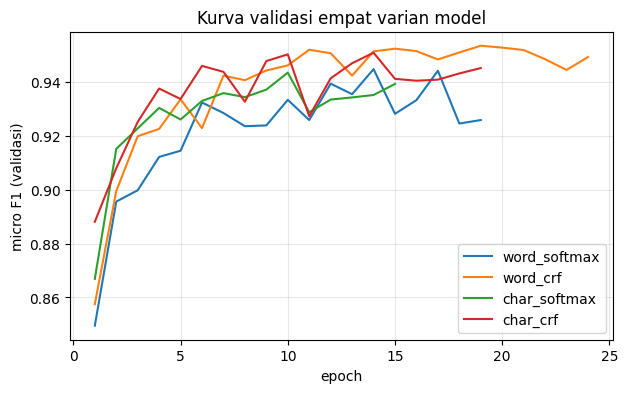

In [22]:
import matplotlib.pyplot as plt

display(pd.DataFrame([{"model": n, "parameter": h["n_params"], "epoch_terbaik": h["best_epoch"],
                       "val_f1_terbaik": h["best_val_f1"]} for n, h in histories.items()]))

plt.figure(figsize=(7, 4))
for n, h in histories.items():
    plt.plot([e["epoch"] for e in h["history"]], [e["val_f1"] for e in h["history"]], label=n)
plt.xlabel("epoch")
plt.ylabel("micro F1 (validasi)")
plt.title("Kurva validasi empat varian model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## **Evaluasi, Klasifier**

In [23]:
def score_only(records, pred):
    gold = [r["tags"] for r in records]
    rep = classification_report(gold, pred, digits=4, output_dict=True)
    return {"micro_f1": round(f1_score(gold, pred), 4),
            "per_entity": {k: {m: round(v[m], 4) for m in ("precision", "recall", "f1-score")}
                           for k, v in rep.items() if k in ENTITY_LABELS}}


eval_sets = {"val": val, "test": test}
if hw:
    eval_sets["handwritten"] = hw

MODEL_NAMES = ["word_softmax", "word_crf", "char_softmax", "char_crf"]
eval_scores, loaded = {}, {}
for name in MODEL_NAMES:
    loaded[name] = load_checkpoint(f"models/{name}.pt")
    model, wv, cv = loaded[name]
    eval_scores[name] = {s: score_only(recs, predict_records(model, recs, wv, cv))
                         for s, recs in eval_sets.items()}
    json.dump(eval_scores[name], open(f"docs/eval_{name}.json", "w"), indent=2)

rows = [[n] + [eval_scores[n].get(k, {}).get("micro_f1") for k in ("val", "test", "handwritten")]
        for n in MODEL_NAMES]
rows.append(["baseline_aturan"] + [baseline_scores.get(k, {}).get("micro_f1")
                                   for k in ("val", "test", "handwritten")])
summary = pd.DataFrame(rows, columns=["model", "val", "test_sintetis", "tulisan_tangan"])
display(summary)

# F1 per entitas
for sname in ("test", "handwritten"):
    if sname not in eval_sets:
        continue
    df = pd.DataFrame({n: {l: eval_scores[n][sname]["per_entity"].get(l, {}).get("f1-score")
                           for l in ENTITY_LABELS} for n in MODEL_NAMES})
    df["baseline"] = [baseline_scores.get(sname, {}).get("per_entity", {}).get(l, {}).get("f1-score")
                      for l in ENTITY_LABELS]
    print(f"\nF1 per entitas: {sname}")
    display(df)

,model,val,test_sintetis,tulisan_tangan
0,word_softmax,0.9448,0.9669,0.6271
1,word_crf,0.9535,0.9642,0.6507
2,char_softmax,0.9435,0.9255,0.6242
3,char_crf,0.9509,0.9349,0.6263
4,baseline_aturan,0.9773,0.9787,0.6880



F1 per entitas: test


,word_softmax,word_crf,char_softmax,char_crf,baseline
NAMA_PERSONALISASI,0.8263,0.8816,0.6774,0.6346,0.9776
PRODUK,0.9894,0.9912,0.9846,0.9919,0.9671
JUMLAH,0.9702,0.9755,0.9791,0.9843,0.9900
WARNA,0.9746,0.9727,0.8806,0.9145,0.9787
UKURAN,0.9956,0.9868,0.9630,0.9585,0.9955
TENGGAT,0.9836,0.9881,0.9756,0.9409,0.9795
TEKS_KARTU,1.0000,0.8049,1.0000,1.0000,1.0000
PENERIMA_ACARA,0.9825,0.9854,0.7704,0.9435,0.9501



F1 per entitas: handwritten


,word_softmax,word_crf,char_softmax,char_crf,baseline
NAMA_PERSONALISASI,0.5143,0.6286,0.5405,0.5294,0.6000
PRODUK,0.7143,0.6905,0.7262,0.7515,0.7403
JUMLAH,0.7000,0.8116,0.7568,0.7467,0.7347
WARNA,0.8056,0.8406,0.7429,0.6944,0.8000
UKURAN,0.6667,0.7273,0.6364,0.5714,0.9167
TENGGAT,0.5217,0.6087,0.7619,0.6087,0.8235
TEKS_KARTU,1.0000,1.0000,1.0000,1.0000,1.0000
PENERIMA_ACARA,0.1270,0.0968,0.0580,0.0952,0.0976


## **Analisis Kesalahan Model Terpilih**

In [24]:
FINAL_MODEL = "word_crf"


def audit(name, records, max_show=25):
    """'+ model saja' = model menandai tapi gold tidak; '- gold saja' = gold ada tapi model lewat."""
    model, wv, cv = loaded[name]
    pred = predict_records(model, records, wv, cv)
    shown = 0
    for r, p in zip(records, pred):
        g, q = set(extract_spans(r["tokens"], r["tags"])), set(extract_spans(r["tokens"], p))
        if g == q:
            continue
        print(r["text"])
        for l, t in sorted(q - g):
            print("   + model saja :", l, repr(t))
        for l, t in sorted(g - q):
            print("   - gold saja  :", l, repr(t))
        shown += 1
        if shown >= max_show:
            break
    print(f"\n({shown} pesan ditampilkan)")


if hw:
    audit(FINAL_MODEL, hw)

mau bikin sajadh sajadah sbg souvenir umroh
   + model saja : JUMLAH 'sajadh'
   + model saja : PENERIMA_ACARA 'umroh'
   + model saja : PRODUK 'sajadah sbg'
   - gold saja  : PENERIMA_ACARA 'souvenir umroh'
   - gold saja  : PRODUK 'sajadah'
permisi kak mau order 5 sajadah custom untuk acara pengajian
   + model saja : PENERIMA_ACARA 'untuk acara pengajian'
   + model saja : PRODUK 'sajadah'
   - gold saja  : PENERIMA_ACARA 'pengajian'
   - gold saja  : PRODUK 'sajadah custom'
sjdh sajadah ini rencananya untuk jamaah masjid
   + model saja : JUMLAH 'ini rencananya'
   + model saja : PENERIMA_ACARA 'untuk jamaah'
   - gold saja  : PENERIMA_ACARA 'jamaah masjid'
kak sajadah yg 60x100 ada? mau warna cream
   + model saja : WARNA '60x100'
   - gold saja  : UKURAN '60x100'
min tolong buatin sajadah bordir nama Pak Hendra selesai 10 desember
   + model saja : NAMA_PERSONALISASI 'Pak'
   - gold saja  : NAMA_PERSONALISASI 'Pak Hendra'
mau order 10 pcs sajadah buat souvenir nikahan, warna dust

## **Klasifier Jenis Pesanan**

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report as sk_report, f1_score as sk_f1, confusion_matrix
import joblib

clf = Pipeline([
    # n-gram KARAKTER supaya tahan typo ("sajdah", "hameprs")
    ("tfidf", TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5),
                              sublinear_tf=True, min_df=2)),
    ("lr", LogisticRegression(max_iter=2000, C=5.0, class_weight="balanced")),
])
clf.fit([r["text"] for r in train], [r["order_type"] for r in train])
joblib.dump(clf, "models/order_clf.joblib")

_TERMS = sorted(PRODUCT_TERMS, key=len, reverse=True)


def rule_predict(text):
    """Pembanding: aturan kata kunci produk (tanpa belajar)."""
    t = text.lower()
    for term in _TERMS:
        if term in t:
            return PRODUCT_TERMS[term]
    return "Other"


def predict_order(text):
    proba = clf.predict_proba([text])[0]
    i = int(proba.argmax())
    return str(clf.classes_[i]), float(proba[i])


clf_scores = {}
for sname, recs in (("val", val), ("test", test), ("handwritten", hw)):
    recs = [r for r in recs if r.get("order_type")]
    if not recs:
        continue
    X, y = [r["text"] for r in recs], [r["order_type"] for r in recs]
    pred, rule = list(clf.predict(X)), [rule_predict(x) for x in X]
    print(f"\n===== Klasifier | {sname} ({len(recs)} pesan) =====")
    print(sk_report(y, pred, digits=3, zero_division=0))
    print("Confusion matrix (baris=gold, kolom=pred), urutan:", ORDER_TYPES)
    print(confusion_matrix(y, pred, labels=ORDER_TYPES))
    clf_scores[sname] = {
        "model_macro_f1": round(sk_f1(y, pred, average="macro"), 4),
        "model_accuracy": round(sum(p == g for p, g in zip(pred, y)) / len(y), 4),
        "rule_macro_f1": round(sk_f1(y, rule, average="macro"), 4),
        "rule_accuracy": round(sum(p == g for p, g in zip(rule, y)) / len(y), 4)}
    if sname == "handwritten":
        print("\nContoh salah:")
        for x, g, p in [t for t in zip(X, y, pred) if t[1] != t[2]][:8]:
            print(f"  gold={g} | pred={p} | {x}")

json.dump(clf_scores, open("docs/clf_scores.json", "w"), indent=2)
display(pd.DataFrame(clf_scores).T)


===== Klasifier | val (800 pesan) =====
                precision    recall  f1-score   support

 Custom Handuk      1.000     1.000     1.000       232
Custom Sajadah      1.000     1.000     1.000       152
       Hampers      1.000     1.000     1.000       201
         Other      1.000     1.000     1.000       137
   Ready Stock      1.000     1.000     1.000        78

      accuracy                          1.000       800
     macro avg      1.000     1.000     1.000       800
  weighted avg      1.000     1.000     1.000       800

Confusion matrix (baris=gold, kolom=pred), urutan: ['Ready Stock', 'Custom Sajadah', 'Custom Handuk', 'Hampers', 'Other']
[[ 78   0   0   0   0]
 [  0 152   0   0   0]
 [  0   0 232   0   0]
 [  0   0   0 201   0]
 [  0   0   0   0 137]]

===== Klasifier | test (800 pesan) =====
                precision    recall  f1-score   support

 Custom Handuk      1.000     1.000     1.000       214
Custom Sajadah      1.000     1.000     1.000       183
   

,model_macro_f1,model_accuracy,rule_macro_f1,rule_accuracy
val,1.0000,1.0000,0.9703,0.9700
test,1.0000,1.0000,0.9758,0.9762
handwritten,0.6154,0.7471,0.7110,0.7931


## **Demo Inference**

In [26]:
def spans_from_tags(tags):
    """BIO -> [(label, start_token, end_token_eksklusif)]. I- tanpa B- dianggap awal span."""
    spans, cur = [], None
    for i, tag in enumerate(tags):
        if tag == "O":
            if cur:
                spans.append(tuple(cur)); cur = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "B" or cur is None or cur[0] != label:
            if cur:
                spans.append(tuple(cur))
            cur = [label, i, i + 1]
        else:
            cur[2] = i + 1
    if cur:
        spans.append(tuple(cur))
    return spans


def extract(text, model_name=FINAL_MODEL, low_conf=0.60):
    model, wv, cv = loaded[model_name]
    toks = tokenize_with_offsets(text)
    batch = {k: v.to(device) for k, v in make_batch([[t for t, _, _ in toks]], wv, cv).items()}
    paths, tok_conf, seq_conf = model.decode_with_conf(batch)
    tags = [ID2TAG[i] for i in paths[0]]
    ents, low = {l: [] for l in ENTITY_LABELS}, []
    for label, a, b_ in spans_from_tags(tags):
        ents[label].append(text[toks[a][1]:toks[b_ - 1][2]])
        if min(tok_conf[0][a:b_]) < low_conf and label not in low:
            low.append(label)
    jenis, jc = predict_order(text)
    return {"jenis_pesanan": jenis, "entitas": {k: v for k, v in ents.items() if v},
            "field_wajib_kosong": missing_fields(ents, jenis),
            "perlu_dicek_admin": low, "sentence_confidence": round(seq_conf[0], 4)}


for msg in [
    "halo kak, mau pesan sajadah travel 2 pcs nama Aisyah warna navy ukuran 70x140 butuh tanggal 20 november",
    'kak mau pesan hampers lebaran 10 set untuk ibu kartunya "Selamat Idul Fitri"',
    "min, sjadah bordir 2 pc nm Dewi wrn maroon tgl 5 des",
    "kak mau pesan sajadah 2 pcs",
]:
    print(msg)
    print(json.dumps(extract(msg), indent=2, ensure_ascii=False), "\n")

halo kak, mau pesan sajadah travel 2 pcs nama Aisyah warna navy ukuran 70x140 butuh tanggal 20 november
{
  "jenis_pesanan": "Custom Sajadah",
  "entitas": {
    "NAMA_PERSONALISASI": [
      "Aisyah"
    ],
    "PRODUK": [
      "sajadah travel"
    ],
    "JUMLAH": [
      "2 pcs"
    ],
    "WARNA": [
      "navy"
    ],
    "UKURAN": [
      "70x140"
    ],
    "TENGGAT": [
      "tanggal 20 november"
    ]
  },
  "field_wajib_kosong": [],
  "perlu_dicek_admin": [],
  "sentence_confidence": 0.9997
} 

kak mau pesan hampers lebaran 10 set untuk ibu kartunya "Selamat Idul Fitri"
{
  "jenis_pesanan": "Hampers",
  "entitas": {
    "PRODUK": [
      "hampers lebaran"
    ],
    "JUMLAH": [
      "10 set"
    ],
    "TEKS_KARTU": [
      "Selamat Idul Fitri"
    ],
    "PENERIMA_ACARA": [
      "untuk ibu"
    ]
  },
  "field_wajib_kosong": [
    "TENGGAT"
  ],
  "perlu_dicek_admin": [],
  "sentence_confidence": 0.7353
} 

min, sjadah bordir 2 pc nm Dewi wrn maroon tgl 5 des
{
  "jenis_p

## **Setup API**

In [28]:
!pip -q install "google-genai>=2.12.1,<3.0.0"

import os, hashlib
from google import genai
from google.genai import types

try:
    from kaggle_secrets import UserSecretsClient
    GEMINI_API_KEY = UserSecretsClient().get_secret("GEMINI_API_KEY")
except Exception:
    GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")

gemini = genai.Client(api_key=GEMINI_API_KEY) if GEMINI_API_KEY else None
print("Gemini siap" if gemini else "Kunci belum diatur: ringkasan memakai template")

if gemini:
    print([m.name for m in gemini.models.list() if "flash" in m.name])

Gemini siap
['models/gemini-2.5-flash', 'models/gemini-2.5-flash-lite', 'models/gemini-2.5-flash-image', 'models/gemini-3.1-flash-lite', 'models/gemini-3.1-flash-image', 'models/gemini-3.1-flash-lite-image', 'models/gemini-3.5-flash', 'models/gemini-3.5-flash-lite', 'models/gemini-omni-flash-preview', 'models/gemini-3.6-flash', 'models/gemini-3.7-flash', 'models/gemini-3.8-flash']


## **Fungsi Ringkasan**

In [31]:
GEMINI_MODELS = ["gemini-3.5-flash", "gemini-2.5-flash"]   # dicoba berurutan; sesuaikan dengan daftar di atas
MAX_CALLS = 20                                             # batas panggilan per sesi (hemat kuota)
SUMMARY_CACHE, CALLS = {}, {"n": 0}

DISPLAY = {"NAMA_PERSONALISASI": "Nama personalisasi", "PRODUK": "Produk", "JUMLAH": "Jumlah",
           "WARNA": "Warna", "UKURAN": "Ukuran", "TENGGAT": "Tenggat",
           "TEKS_KARTU": "Teks kartu", "PENERIMA_ACARA": "Penerima/acara"}

SYSTEM_PROMPT = (
    "Kamu menyusun ringkasan pesanan untuk admin toko hampers dan hadiah personalisasi. "
    "Gunakan HANYA data pada JSON yang diberikan. Jangan menambah, menebak, atau mengubah "
    "informasi apa pun (nama, angka, tanggal, warna). Jika sebuah field wajib masih kosong, "
    "sebutkan bahwa informasinya belum ada. Tulis 2-3 kalimat bahasa Indonesia yang ringkas."
)


def template_summary(data):
    """Ringkasan tanpa LLM: cadangan kalau API gagal atau ditolak pemeriksaan."""
    lines = [f"Jenis pesanan: {data['jenis_pesanan']}."]
    for label in ENTITY_LABELS:
        vals = data["entitas"].get(label)
        if vals:
            lines.append(f"{DISPLAY[label]}: {', '.join(vals)}.")
    if data["field_wajib_kosong"]:
        lines.append("Belum ada: " + ", ".join(DISPLAY[f] for f in data["field_wajib_kosong"]) + ".")
    return " ".join(lines)


def summary_is_faithful(summary, data):
    """Pemeriksaan sederhana: semua angka di ringkasan harus ada di data terstruktur."""
    allowed = set(re.findall(r"\d+", json.dumps(data, ensure_ascii=False)))
    return all(n in allowed for n in re.findall(r"\d+", summary))


def summarize_order(result, use_llm=True):
    # Input ke LLM hanya JSON terstruktur (bukan chat mentah customer)
    data = {"jenis_pesanan": result["jenis_pesanan"], "entitas": result["entitas"],
            "field_wajib_kosong": result["field_wajib_kosong"]}
    key = hashlib.md5(json.dumps(data, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    if key in SUMMARY_CACHE:
        return SUMMARY_CACHE[key]

    out = {"summary": template_summary(data), "source": "template"}
    if use_llm and gemini and CALLS["n"] < MAX_CALLS:
        last_error = None
        for model_name in GEMINI_MODELS:
            try:
                CALLS["n"] += 1
                resp = gemini.models.generate_content(
                    model=model_name,
                    contents=json.dumps(data, ensure_ascii=False),
                    config=types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT,
                                                       temperature=0.0))
                text = (resp.text or "").strip()
                if text and summary_is_faithful(text, data):
                    out = {"summary": text, "source": f"gemini:{model_name}"}
                    break
                last_error = "ringkasan kosong atau gagal pemeriksaan angka"
            except Exception as e:
                last_error = str(e)[:150]
        if out["source"] == "template" and last_error:
            out["note"] = f"cadangan template dipakai ({last_error})"
    SUMMARY_CACHE[key] = out
    return out

In [32]:
for msg in [
    "halo kak, mau pesan sajadah travel 2 pcs nama Aisyah warna navy ukuran 70x140 butuh tanggal 20 november",
    "kak mau pesan sajadah 2 pcs",
]:
    print(msg)
    print(json.dumps(summarize_order(extract(msg)), indent=2, ensure_ascii=False), "\n")

halo kak, mau pesan sajadah travel 2 pcs nama Aisyah warna navy ukuran 70x140 butuh tanggal 20 november
{
  "summary": "Pesanan Custom Sajadah terdiri dari 2 pcs sajadah travel berwarna navy ukuran 70x140 dengan personalisasi nama \"Aisyah\". Tenggat waktu penyelesaian pesanan ini adalah tanggal 20 november dan seluruh field wajib telah terisi lengkap.",
  "source": "gemini:gemini-3.5-flash"
} 

kak mau pesan sajadah 2 pcs
{
  "summary": "Terdapat pesanan Custom Sajadah sebanyak 2 pcs. Namun, informasi wajib mengenai nama personalisasi, ukuran, dan tenggat waktu pesanan belum ada.",
  "source": "gemini:gemini-3.5-flash"
} 

